In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset

from os import path, listdir
from PIL import Image

import yaml

In [2]:
DatasetRoot = "../Datasets/GTSDB/"

In [3]:
class DS(Dataset):
    def __init__(self, root, split, transform=None):
        self.root = root
        self.transform = transform
        self.imgs = []
        self.labels = []
        self.labelNames = []

        with open(path.join(root, "data.yaml"), 'r') as f:
            data = yaml.load(f, Loader=yaml.SafeLoader)

        imFolder = data[split]
        lFolder = imFolder.replace("images", "labels")
        
        nameList = data.get("names")
        for i in nameList:
            self.labelNames.append(nameList.get(i))
        
        # load all image files, sorting them to ensure that they are aligned
        for imName in list(sorted(listdir(path.join(root, imFolder)))):
            im = Image.open(path.join(root, imFolder, imName))
            imLabels = []
            with open(path.join(root, lFolder, imName.replace(".jpg", ".txt")), 'r') as file:
                for line in file:
                    l, x, y, w, h = line.strip().split(" ")
                    t = (int(l), float(x), float(y), float(w), float(h))
                    imLabels.append(t)

            self.imgs.append(im)
            self.labels.append(imLabels)

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        sample = self.imgs[idx]
        label = self.labels[idx]
        
        if self.transform:
            sample = self.transform(sample)

        return sample, label

In [4]:
Data = DS(DatasetRoot, "train")

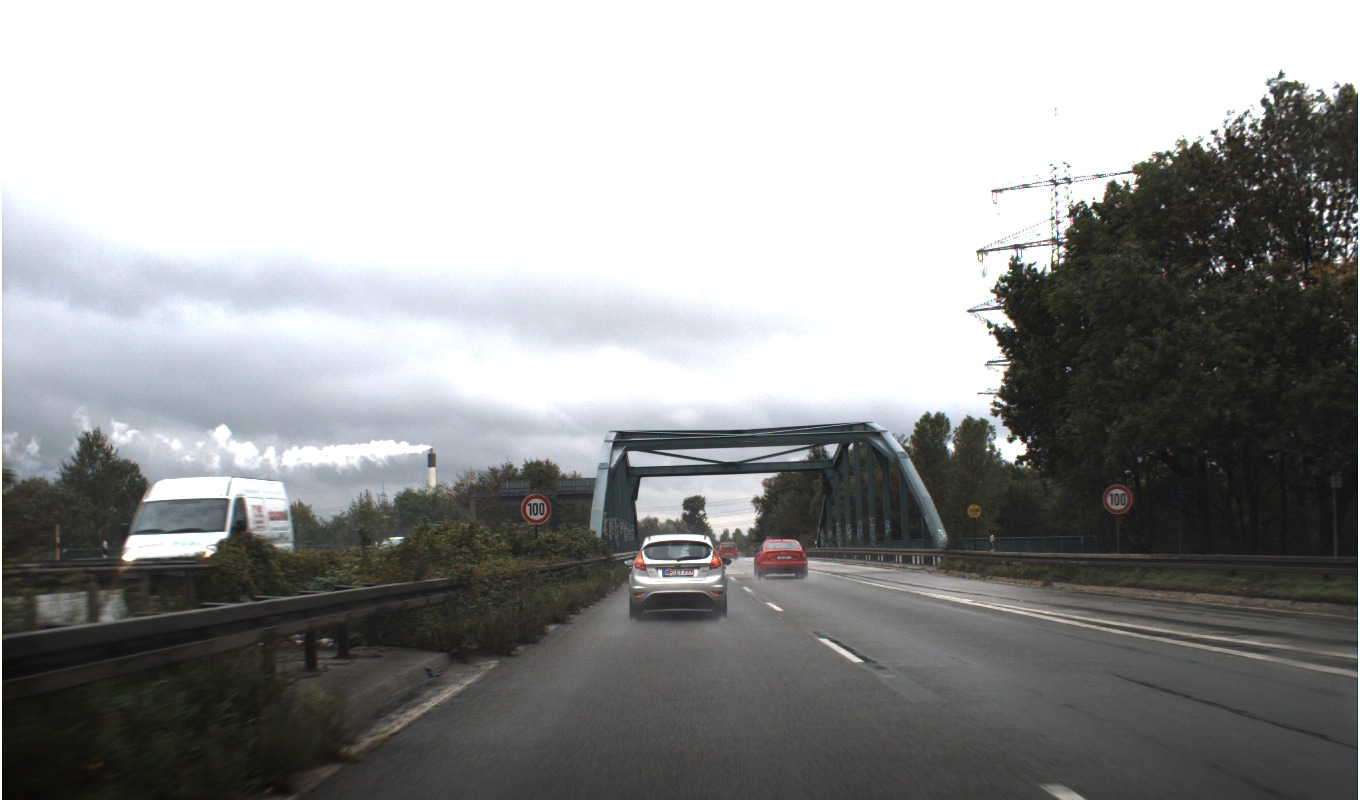

In [5]:
display(Data[0][0])

In [6]:
print(Data[0][1])

[(32, 0.39336, 0.63561, 0.02353, 0.04125), (32, 0.82165, 0.62499, 0.02422, 0.04248)]
